In [ ]:
%pip install shap
%pip install --force-reinstall "numpy<2" pandas pyarrow shap


In [4]:
import sys

!"{sys.executable}" -m pip install --force-reinstall --no-cache-dir "numpy==1.26.4" "pandas<2.3" pyarrow shap numba scipy

In [4]:
import os
import joblib
import numpy as np
import pandas as pd
import shap
from pathlib import Path

CUR_DIR = Path.cwd().resolve()
BASE_DIR = CUR_DIR / "data"


DRIVE_DIR = BASE_DIR
CHECKPOINT_DIR = CUR_DIR / "result" / "step2_model"
SAVE_DIR = CHECKPOINT_DIR / "saved_models_v6"
FEATURE_ENGINEERED_PATH = os.path.join(DRIVE_DIR, '2단계_학습데이터_최종_인허가포함_피처완료.parquet')

TARGET_COL = '최종_보정라벨'
QUARTER_COL = '기준_년분기'
ID_COL = '상가업소번호'


## 1. 모델 + 데이터 로드

In [5]:
final_model = joblib.load(os.path.join(SAVE_DIR, 'final_model_for_shap.pkl'))
final_calibrator = joblib.load(os.path.join(SAVE_DIR, 'final_calibrator_for_service.pkl'))
FEATURE_COLS = joblib.load(os.path.join(SAVE_DIR, 'feature_cols.pkl'))

df = pd.read_parquet(FEATURE_ENGINEERED_PATH)   
print(f'✅ 로드 완료: {df.shape}, 피처 {len(FEATURE_COLS)}개')

ALL_QUARTERS = sorted(df[QUARTER_COL].unique())
TARGET_QUARTER = ALL_QUARTERS[-1]
print(f'대상 분기: {TARGET_QUARTER}')


✅ 로드 완료: (6041091, 70), 피처 49개
대상 분기: 2024Q4


In [6]:
target_df = df[df[QUARTER_COL] == TARGET_QUARTER].copy()
X_target = target_df[FEATURE_COLS]
print(f'대상 매장 수: {len(target_df):,}')


대상 매장 수: 553,535


## 2. 폐업확률 + Risk Tier

In [7]:
target_df['폐업확률'] = final_calibrator.predict_proba(X_target)[:, 1]

q_critical = target_df['폐업확률'].quantile(0.95)
q_high = target_df['폐업확률'].quantile(0.85)
q_medium = target_df['폐업확률'].quantile(0.70)

print(f"Risk Tier 임계값 (이번 분기 기준) — Critical: {q_critical:.4f} / High: {q_high:.4f} / Medium: {q_medium:.4f}")

if q_medium == 0:
    print("⚠️ 폐업확률 0인 매장이 많아 하위 70% 분위수가 0으로 계산되었습니다.")
    print("   이 경우 Medium 이상 그룹 비율이 목표(상위 30%)보다 커질 수 있습니다 — 캘리브레이션 표 확인 후 고정 임계값 전환을 고려하세요.")

def get_risk_tier(p):
    if p >= q_critical:
        return 'Critical'
    elif p >= q_high:
        return 'High'
    elif p >= q_medium:
        return 'Medium'
    return 'Low'

target_df['Risk_Tier'] = target_df['폐업확률'].apply(get_risk_tier)

print(target_df['Risk_Tier'].value_counts())
print((target_df['Risk_Tier'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')


Risk Tier 임계값 (이번 분기 기준) — Critical: 0.2182 / High: 0.0765 / Medium: 0.0429
Risk_Tier
Low         386765
Medium       82030
High         56708
Critical     28032
Name: count, dtype: int64
Risk_Tier
Low         69.87%
Medium      14.82%
High        10.24%
Critical     5.06%
Name: proportion, dtype: object


## 3. SHAP 위험요인

In [8]:
at_risk_mask = target_df['Risk_Tier'].isin(['Critical', 'High'])
at_risk_df = target_df[at_risk_mask].copy()
X_at_risk = at_risk_df[FEATURE_COLS]
print(f'SHAP 계산 대상(Critical/High만): {len(at_risk_df):,}건')

explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_at_risk)
if isinstance(shap_values, list):
    shap_values = shap_values[1]
shap_df = pd.DataFrame(shap_values, columns=FEATURE_COLS, index=at_risk_df.index)


SHAP 계산 대상(Critical/High만): 84,740건


## 3-1. 위험요인 카테고리 분류 

In [9]:
FEATURE_CATEGORY_MAP = {
    '1단계_위험점수': '상권쇠퇴', '1단계_위험점수_diff1': '상권쇠퇴', '1단계_위험점수_pct1': '상권쇠퇴',
    '1단계_위험점수_diff4': '상권쇠퇴', '1단계_위험점수_roll_std_4q': '상권쇠퇴',
    '상권_누적_폐업률': '상권쇠퇴', '상권_대비_업종_폐업률_차이': '상권쇠퇴',
    '1단계위험_x_100m이웃차이': '상권쇠퇴',

    '업종_직전분기_폐업률': '업종구조위험', '업종_누적_폐업률': '업종구조위험',
    '인허가대상업종여부': '업종구조위험',

    '건물내총업소수': '건물내경쟁밀집', '건물내총업소수_diff1': '건물내경쟁밀집', '건물내총업소수_pct1': '건물내경쟁밀집',
    '건물내업종다양성_entropy': '건물내경쟁밀집',

    '반경100m_업종다양성': '반경경쟁밀집', '반경100m_업종다양성_diff1': '반경경쟁밀집', '반경100m_업종다양성_pct1': '반경경쟁밀집',
    '반경100m_이웃수': '반경경쟁밀집', '반경100m_이웃수_diff1': '반경경쟁밀집', '반경100m_이웃수_pct1': '반경경쟁밀집',
    '반경100m_이웃수_diff4': '반경경쟁밀집', '반경100m_이웃수_대비_4분기평균비율': '반경경쟁밀집',
    '반경250m_업종다양성': '반경경쟁밀집',
    '반경250m_이웃수': '반경경쟁밀집', '반경250m_이웃수_diff1': '반경경쟁밀집', '반경250m_이웃수_pct1': '반경경쟁밀집',
    '건물대비_100m이웃_비율': '반경경쟁밀집', '업종다양성_대비_이웃수': '반경경쟁밀집',

    '건물명존재여부': '입지특성', '지상1층여부': '입지특성', '지하여부': '입지특성', '반지하여부': '입지특성',

    '업력_개월': '업력신생리스크', '데이터내_누적분기수': '업력신생리스크',
}

EXCLUDE_FROM_REASON = [
    '층호결합추정여부', '층정보파싱실패여부', '층정보결측여부',
    '건물내표본수부족여부', '건물관리번호결측여부',
    '1단계_공간매칭실패여부', '1단계_업종매칭실패여부', '1단계_대체수준_1', '1단계_대체수준_2',
    '매칭등급_A', '지점여부',
    '분기_Q2여부', '분기_Q3여부', '분기_Q4여부',
]

FEATURE_LABEL_MAP = {
    '1단계_위험점수': '상권 위험도', '1단계_위험점수_diff1': '상권 위험도 최근 악화',
    '1단계_위험점수_diff4': '상권 위험도 전년대비 악화', '1단계_위험점수_roll_std_4q': '상권 불안정성',
    '상권_누적_폐업률': '상권 누적 폐업률', '상권_대비_업종_폐업률_차이': '상권 특이 위험(업종평균 대비)',
    '1단계위험_x_100m이웃차이': '상권-경쟁 복합 위험',
    '업종_직전분기_폐업률': '업종 트렌드 악화', '업종_누적_폐업률': '업종 구조적 위험', '인허가대상업종여부': '업종 특성',
    '건물내총업소수': '건물 내 경쟁 밀집도', '건물내업종다양성_entropy': '건물 내 업종 다양성',
    '반경100m_이웃수': '주변(100m) 경쟁 밀집도', '반경100m_이웃수_diff1': '주변(100m) 경쟁 급증',
    '반경100m_업종다양성': '주변(100m) 업종 다양성',
    '반경250m_이웃수': '광역(250m) 경쟁 밀집도', '반경250m_업종다양성': '광역(250m) 업종 다양성',
    '건물대비_100m이웃_비율': '건물 대비 상대적 밀집도', '업종다양성_대비_이웃수': '업종 대비 경쟁 밀집도',
    '건물명존재여부': '건물 식별정보', '지상1층여부': '1층 입지', '지하여부': '지하 입지', '반지하여부': '반지하 입지',
    '업력_개월': '업력 리스크(신생)', '데이터내_누적분기수': '영업 지속기간',
}

CONDITIONAL_INVALID_FEATURES = {
    '건물관리번호결측여부': ['건물내총업소수', '건물내총업소수_diff1', '건물내총업소수_pct1', '건물내업종다양성_entropy'],
    '건물내표본수부족여부': ['건물내업종다양성_entropy'],  
}

MIN_CONTRIBUTION_RATIO = 0.12

_shap_candidates = shap_df.drop(columns=[c for c in EXCLUDE_FROM_REASON if c in shap_df.columns], errors='ignore')

for _flag_col, _invalid_cols in CONDITIONAL_INVALID_FEATURES.items():
    if _flag_col not in X_at_risk.columns:
        continue
    _mask = (X_at_risk[_flag_col] == 1)
    _n_masked = int(_mask.sum())
    if _n_masked > 0:
        print(f"'{_flag_col}'==1 인 매장 {_n_masked:,}건 -> {_invalid_cols} 위험요인 후보에서 제외 처리")
    for _col in _invalid_cols:
        if _col in _shap_candidates.columns:
            _shap_candidates.loc[_mask, _col] = 0.0

FEATURE_SCALE = _shap_candidates.where(_shap_candidates > 0).mean()

_all_positive_values = _shap_candidates.values[_shap_candidates.values > 0]
ABSOLUTE_FLOOR = float(np.median(_all_positive_values))
print(f"ABSOLUTE_FLOOR(그룹 전체 양수 SHAP 중앙값): {ABSOLUTE_FLOOR:.6f}")


def get_risk_factors_v3(row):
    positive = row[row > 0]
    if len(positive) == 0:
        return '뚜렷한 위험요인 없음', '기타', None, None

    total_positive = positive.sum()

    top1_col = positive.idxmax()
    label1 = FEATURE_LABEL_MAP.get(top1_col, top1_col)
    cat1 = FEATURE_CATEGORY_MAP.get(top1_col, '기타')

    remaining = positive.drop(labels=[top1_col])
    remaining = remaining[
        (remaining >= MIN_CONTRIBUTION_RATIO * total_positive) &
        (remaining >= ABSOLUTE_FLOOR)
    ]

    if len(remaining) == 0:
        return label1, cat1, None, None

    def _normalize(col, val):
        scale = FEATURE_SCALE.get(col)
        if pd.isna(scale) or scale == 0:
            return val
        return val / scale

    normalized = pd.Series({c: _normalize(c, remaining[c]) for c in remaining.index})
    top2_col = normalized.idxmax()
    label2 = FEATURE_LABEL_MAP.get(top2_col, top2_col)
    cat2 = FEATURE_CATEGORY_MAP.get(top2_col, '기타')

    return label1, cat1, label2, cat2


_results = _shap_candidates.apply(get_risk_factors_v3, axis=1, result_type='expand')
_results.columns = ['위험요인', '위험카테고리', '위험요인_2위', '위험카테고리_2위']
at_risk_df['위험요인'] = _results['위험요인']
at_risk_df['위험카테고리'] = _results['위험카테고리']
at_risk_df['위험요인_2위'] = _results['위험요인_2위']
at_risk_df['위험카테고리_2위'] = _results['위험카테고리_2위']

print('[배경위험] 카테고리 분포 (표시용, 액션 결정엔 미사용)')
print(at_risk_df['위험카테고리'].value_counts())
print()
print('[주요대응근거] 카테고리 분포 (실제 액션 결정 기준, 해당사항 있는 매장만)')
print(at_risk_df['위험카테고리_2위'].value_counts(dropna=True))
print(f"주요대응근거가 없어 배경위험으로 대체되는 매장 수: {at_risk_df['위험카테고리_2위'].isna().sum():,}건")

target_df['위험요인'] = '해당없음(Medium/Low)'
target_df['위험카테고리'] = '해당없음'
target_df['위험요인_2위'] = None
target_df['위험카테고리_2위'] = None
for col in ['위험요인', '위험카테고리', '위험요인_2위', '위험카테고리_2위']:
    target_df.loc[at_risk_df.index, col] = at_risk_df[col]


'건물관리번호결측여부'==1 인 매장 1,488건 -> ['건물내총업소수', '건물내총업소수_diff1', '건물내총업소수_pct1', '건물내업종다양성_entropy'] 위험요인 후보에서 제외 처리
'건물내표본수부족여부'==1 인 매장 17,803건 -> ['건물내업종다양성_entropy'] 위험요인 후보에서 제외 처리
ABSOLUTE_FLOOR(그룹 전체 양수 SHAP 중앙값): 0.014979
[배경위험] 카테고리 분포 (표시용, 액션 결정엔 미사용)
위험카테고리
업력신생리스크    81916
업종구조위험      2129
상권쇠퇴         424
건물내경쟁밀집      267
반경경쟁밀집         4
Name: count, dtype: int64

[주요대응근거] 카테고리 분포 (실제 액션 결정 기준, 해당사항 있는 매장만)
위험카테고리_2위
업종구조위험     43657
업력신생리스크    17987
상권쇠퇴        2811
건물내경쟁밀집     2799
반경경쟁밀집        39
입지특성           7
Name: count, dtype: int64
주요대응근거가 없어 배경위험으로 대체되는 매장 수: 17,440건


## 3-2. SHAP 변수 중요도 

영업 지속기간                  0.532618
업종 트렌드 악화                0.245173
업력 리스크(신생)               0.136255
상권 위험도 전년대비 악화           0.066087
상권 불안정성                  0.062169
반경100m_이웃수_대비_4분기평균비율    0.061610
상권 위험도                   0.060052
업종 구조적 위험                0.055331
1단계_위험점수_pct1            0.050089
건물 식별정보                  0.035481
상권 위험도 최근 악화             0.034643
반경250m_이웃수_diff1         0.025596
주변(100m) 경쟁 급증           0.024619
업종 특성                    0.021809
반경100m_이웃수_diff4         0.019366
dtype: float64


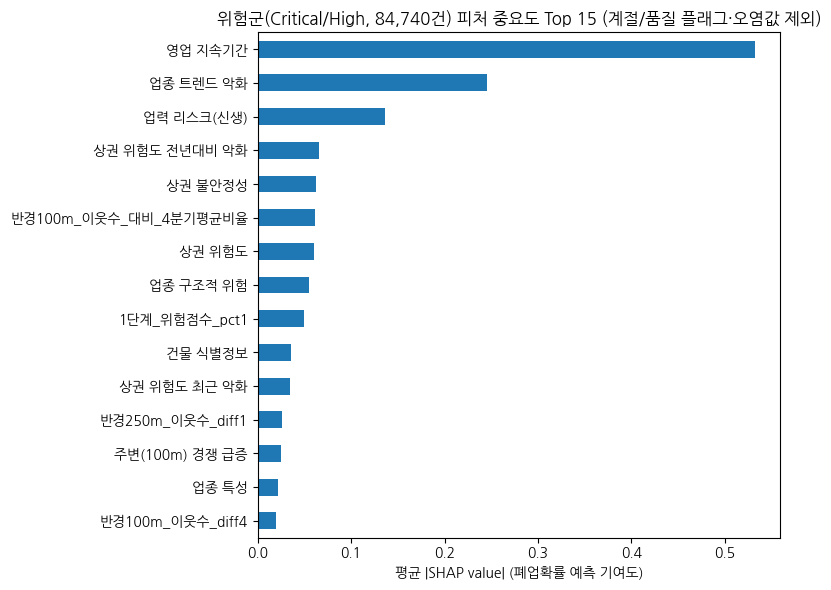

In [10]:
import subprocess, os
subprocess.run("apt-get -qq install -y fonts-nanum > /dev/null 2>&1", shell=True)

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

nanum_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
if os.path.exists(nanum_path):
    fm.fontManager.addfont(nanum_path)
    plt.rcParams['font.family'] = 'NanumGothic'
else:
    for _font in ['NanumGothic', 'NanumBarunGothic', 'AppleGothic', 'Malgun Gothic']:
        if any(_font in f.name for f in fm.fontManager.ttflist):
            plt.rcParams['font.family'] = _font
            break
plt.rcParams['axes.unicode_minus'] = False


shap_importance = _shap_candidates.abs().mean().sort_values(ascending=False)

shap_importance_display = shap_importance.rename(index=lambda c: FEATURE_LABEL_MAP.get(c, c))

TOP_N = 15
top_importance = shap_importance_display.head(TOP_N)
print(top_importance)

plt.figure(figsize=(8, 6))
top_importance.sort_values().plot(kind='barh')
plt.xlabel('평균 |SHAP value| (폐업확률 예측 기여도)')
plt.title(f'위험군(Critical/High, {len(at_risk_df):,}건) 피처 중요도 Top {TOP_N} (계절/품질 플래그·오염값 제외)')
plt.tight_layout()
plt.show()


## 4. 초과취약도 (상권-업종 기본 위험도 대비)


In [11]:

if '1단계_위험점수' in target_df.columns:
    baseline = target_df['1단계_위험점수'] / 100
    target_df['초과취약도'] = target_df['폐업확률'] - baseline
else:
    peer_avg = target_df.groupby('서비스_업종_코드')['폐업확률'].transform('mean')
    target_df['초과취약도'] = target_df['폐업확률'] - peer_avg
    print("⚠️ '1단계_위험점수' 컬럼이 없어 업종 평균 대비 방식으로 대체했습니다.")

print(target_df['초과취약도'].describe())


count    553535.000000
mean          0.028664
std           0.088469
min          -0.269659
25%          -0.004781
50%           0.004118
75%           0.022099
max           0.999704
Name: 초과취약도, dtype: float64


## 5. 추천 Action (임시 규칙)

In [12]:
ACTION_BY_CATEGORY = {
    '상권쇠퇴': '상권 이전 특별대출 안내 + 인근 유망상권 입지 컨설팅',
    '업종구조위험': '업종전환 특화대출 + 사업재편자금 연계',
    '건물내경쟁밀집': '리브랜딩/인테리어 자금대출 + 매출연동 소액대출',
    '반경경쟁밀집': '온라인·배달채널 전환 지원대출 + 디지털전환 자금 안내',
    '입지특성': '입지개선(이전/리모델링) 자금대출 + 임차보증금 대출 우대',
    '업력신생리스크': '청년·초기창업 특례보증대출 + 창업초기 금리우대 프로그램',
    '기타': '정책자금 안내 + 개별 경영상담',
}

EXCESS_VULN_HIGH = 0.10   
EXCESS_VULN_LOW = -0.05   


def get_excess_vuln_modifier(excess_vuln):
    if pd.isna(excess_vuln):
        return ''
    if excess_vuln >= EXCESS_VULN_HIGH:
        return ' + 개별 경영진단 및 대출 상환유예·만기연장 우선 검토(가게 자체 위험 요인 큼)'
    elif excess_vuln <= EXCESS_VULN_LOW:
        return ' + 이전자금대출 및 동일상권 내 대체 입지 매칭 지원(상권 자체가 부진, 가게는 상대적으로 선방 중)'
    return ''


def get_recommended_action(tier, background_category, primary_category, excess_vuln):
    if tier == 'Medium':
        return '경영 모니터링 강화'
    if tier == 'Low':
        return '정기 모니터링'


    effective_category = primary_category if primary_category is not None else background_category
    base_action = ACTION_BY_CATEGORY.get(effective_category, ACTION_BY_CATEGORY['기타'])

    background_note = ''
    if background_category is not None and background_category != effective_category:
        background_note = f' (배경위험: {background_category})'

    modifier = get_excess_vuln_modifier(excess_vuln)
    return base_action + modifier + background_note


target_df['추천_Action'] = target_df.apply(
    lambda r: get_recommended_action(r['Risk_Tier'], r['위험카테고리'], r['위험카테고리_2위'], r['초과취약도']), axis=1
)


## 6. 최종 결과표

In [13]:
result = target_df[[
    ID_COL, '상권_코드_명', '서비스_업종_코드_명',
    '폐업확률', 'Risk_Tier', '위험카테고리', '위험요인', '위험카테고리_2위', '위험요인_2위',
    '초과취약도', '추천_Action'
]].copy()
result = result.sort_values('폐업확률', ascending=False)

result_display = result.copy()
result_display['폐업확률'] = (result_display['폐업확률'] * 100).round(1).astype(str) + '%'
result_display['초과취약도'] = (result_display['초과취약도'] * 100).round(1).apply(
    lambda x: f"{'+' if x >= 0 else ''}{x}%"
)

print(result_display.head(20))


                       상가업소번호    상권_코드_명 서비스_업종_코드_명    폐업확률 Risk_Tier  \
5970945  MA0106202201A1930205    후암동주민센터         화장품  100.0%  Critical   
5986729  MA0106202301A0053386      구로세무서        의료기기  100.0%  Critical   
5971826  MA0106202201A2054332        성수역     운동/경기용품  100.0%  Critical   
6008671  MA0106202301A1674884        세검정        의료기기  100.0%  Critical   
5972025  MA0106202201A2066267       방이시장         화장품  100.0%  Critical   
5971137  MA0106202201A1954143     서울대입구역        의료기기  100.0%  Critical   
6032438  MA0106202406A2465510  여의도역(여의도)       커피-음료   95.6%  Critical   
6032339  MA0106202406A2465141      이화사거리       커피-음료   95.6%  Critical   
6010816  MA0106202301A2072069    우장산역 4번       한식음식점   95.6%  Critical   
6010817  MA0106202301A2072225        NaN       기타오락장   95.6%  Critical   
6032346  MA0106202406A2465149      한남오거리       커피-음료   95.6%  Critical   
6032344  MA0106202406A2465147       신논현역       커피-음료   95.6%  Critical   
6032342  MA0106202406A2465145        N

## 6-1. 대표 사례 샘플 (카테고리별)

In [14]:
pd.set_option('display.max_colwidth', None)

sample_cols = [
    ID_COL, '서비스_업종_코드_명', '폐업확률', 'Risk_Tier',
    '위험카테고리', '위험요인', '위험카테고리_2위', '위험요인_2위',
    '초과취약도', '추천_Action'
]

result_full = target_df[sample_cols].copy()

result_full['대표카테고리'] = result_full['위험카테고리_2위'].fillna(result_full['위험카테고리'])

N_PER_CATEGORY = 3  

presentation_sample = (
    result_full[result_full['Risk_Tier'].isin(['Critical', 'High'])]
    .sort_values('폐업확률', ascending=False)
    .groupby('대표카테고리', group_keys=False)
    .head(N_PER_CATEGORY)
    .sort_values(['대표카테고리', '폐업확률'], ascending=[True, False])
)

presentation_display = presentation_sample.drop(columns=['대표카테고리']).copy()
presentation_display['폐업확률'] = (presentation_display['폐업확률'] * 100).round(1).astype(str) + '%'
presentation_display['초과취약도'] = (presentation_display['초과취약도'] * 100).round(1).apply(
    lambda x: f"{'+' if x >= 0 else ''}{x}%"
)

print(f"카테고리 {result_full['대표카테고리'].nunique()}개 중 카테고리당 최대 {N_PER_CATEGORY}건씩, 총 {len(presentation_display)}건 샘플")
presentation_display


카테고리 7개 중 카테고리당 최대 3건씩, 총 18건 샘플


,상가업소번호,서비스_업종_코드_명,폐업확률,Risk_Tier,위험카테고리,위험요인,위험카테고리_2위,위험요인_2위,초과취약도,추천_Action
5667694,MA0101202406A0380641,슈퍼마켓,46.0%,Critical,업력신생리스크,영업 지속기간,건물내경쟁밀집,건물내총업소수_pct1,+43.5%,리브랜딩/인테리어 자금대출 + 매출연동 소액대출 + 개별 경영진단 및 대출 상환유예·만기연장 우선 검토(가게 자체 위험 요인 큼) (배경위험: 업력신생리스크)
5695705,MA0101202406A0524814,게스트하우스,46.0%,Critical,업력신생리스크,영업 지속기간,건물내경쟁밀집,건물내총업소수_pct1,+42.9%,리브랜딩/인테리어 자금대출 + 매출연동 소액대출 + 개별 경영진단 및 대출 상환유예·만기연장 우선 검토(가게 자체 위험 요인 큼) (배경위험: 업력신생리스크)
5662916,MA0101202406A0355635,건축물청소,38.0%,Critical,업력신생리스크,영업 지속기간,건물내경쟁밀집,건물내총업소수_pct1,+35.2%,리브랜딩/인테리어 자금대출 + 매출연동 소액대출 + 개별 경영진단 및 대출 상환유예·만기연장 우선 검토(가게 자체 위험 요인 큼) (배경위험: 업력신생리스크)
5668798,MA0101202406A0385955,안경,64.6%,Critical,업력신생리스크,영업 지속기간,반경경쟁밀집,반경250m_이웃수_pct1,+63.3%,온라인·배달채널 전환 지원대출 + 디지털전환 자금 안내 + 개별 경영진단 및 대출 상환유예·만기연장 우선 검토(가게 자체 위험 요인 큼) (배경위험: 업력신생리스크)
6011834,MA0106202301A2185489,한식음식점,61.5%,Critical,업종구조위험,업종 트렌드 악화,반경경쟁밀집,건물 대비 상대적 밀집도,+59.0%,온라인·배달채널 전환 지원대출 + 디지털전환 자금 안내 + 개별 경영진단 및 대출 상환유예·만기연장 우선 검토(가게 자체 위험 요인 큼) (배경위험: 업종구조위험)
5999873,MA0106202301A0601502,분식전문점,50.0%,Critical,업종구조위험,업종 트렌드 악화,반경경쟁밀집,건물 대비 상대적 밀집도,+47.5%,온라인·배달채널 전환 지원대출 + 디지털전환 자금 안내 + 개별 경영진단 및 대출 상환유예·만기연장 우선 검토(가게 자체 위험 요인 큼) (배경위험: 업종구조위험)
6010101,MA0106202301A1994990,변호사사무소,27.6%,Critical,반경경쟁밀집,건물 대비 상대적 밀집도,상권쇠퇴,1단계_위험점수_pct1,+26.4%,상권 이전 특별대출 안내 + 인근 유망상권 입지 컨설팅 + 개별 경영진단 및 대출 상환유예·만기연장 우선 검토(가게 자체 위험 요인 큼) (배경위험: 반경경쟁밀집)
6010068,MA0106202301A1990089,NaN,26.8%,Critical,반경경쟁밀집,건물 대비 상대적 밀집도,상권쇠퇴,1단계_위험점수_pct1,+24.9%,상권 이전 특별대출 안내 + 인근 유망상권 입지 컨설팅 + 개별 경영진단 및 대출 상환유예·만기연장 우선 검토(가게 자체 위험 요인 큼) (배경위험: 반경경쟁밀집)
5684746,MA0101202406A0465677,기타오락장,24.4%,Critical,업력신생리스크,영업 지속기간,상권쇠퇴,상권 위험도,+17.6%,상권 이전 특별대출 안내 + 인근 유망상권 입지 컨설팅 + 개별 경영진단 및 대출 상환유예·만기연장 우선 검토(가게 자체 위험 요인 큼) (배경위험: 업력신생리스크)
5939304,MA0105202301E0693894,피부관리실,95.6%,Critical,업력신생리스크,영업 지속기간,None,None,+93.1%,청년·초기창업 특례보증대출 + 창업초기 금리우대 프로그램 + 개별 경영진단 및 대출 상환유예·만기연장 우선 검토(가게 자체 위험 요인 큼)


In [15]:
ACTION_RESULT_DIR = CUR_DIR / "result" / "action_plan"
ACTION_RESULT_DIR.mkdir(parents=True, exist_ok=True)

ACTION_RESULT_PATH = (
    ACTION_RESULT_DIR / "action_plan_result.csv"
)

REPRESENTATIVE_PATH = (
    ACTION_RESULT_DIR
    / "action_plan_representative_cases.csv"
)

result.to_csv(
    ACTION_RESULT_PATH,
    index=False,
    encoding="utf-8-sig"
)

presentation_display.to_csv(
    REPRESENTATIVE_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("저장 완료:", ACTION_RESULT_PATH)
print("저장 완료:", REPRESENTATIVE_PATH)

저장 완료: .\result\action_plan\action_plan_result.csv
저장 완료: .\result\action_plan\action_plan_representative_cases.csv
